# DroPE: анализ сохранённых экспериментов

CPU-only. Ни обучение, ни загрузка весов здесь не запускаются. Источники: машинные метрики этапов 1–2 и дополнительные console-recovered результаты. Полный протокол: [отчёт](../docs/report.md).

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src/analyze_results.py').exists()
sys.path.insert(0,str(ROOT/'src'))
from analyze_results import load,tables,build,read
import pandas as pd
from IPython.display import display,Image
root,before,after=load(ROOT)
print('Machine evaluations: matching test SHA256 and successful workers.')
comparison=build(ROOT)

Machine evaluations: matching test SHA256 and successful workers.


## Протокол
SmolLM-360M, recalibration 2048, batch 8, LR 3e-5, fp16, ZeRO1, T4×2. Финальный step 18689; бюджет 0.3062B входных токенов против ≥31.46B в статье. Это ограниченное воспроизведение адаптации pretrained SmolLM (§5.1/C.1), не обучение с нуля.

In [2]:
display(tables(ROOT)[3][['stage','final_step','mean_seconds_per_step','peak_allocated_gb']])

,stage,final_step,mean_seconds_per_step,peak_allocated_gb
0,stage1,8712,3.412114,9.248251
1,stage2,18689,3.007177,9.248251


## Обучение и held-out dev
Абсолютные шаги. Вертикальная линия — восстановление на step 8712. Dev используется для выбора beta; test не участвует в подборе.

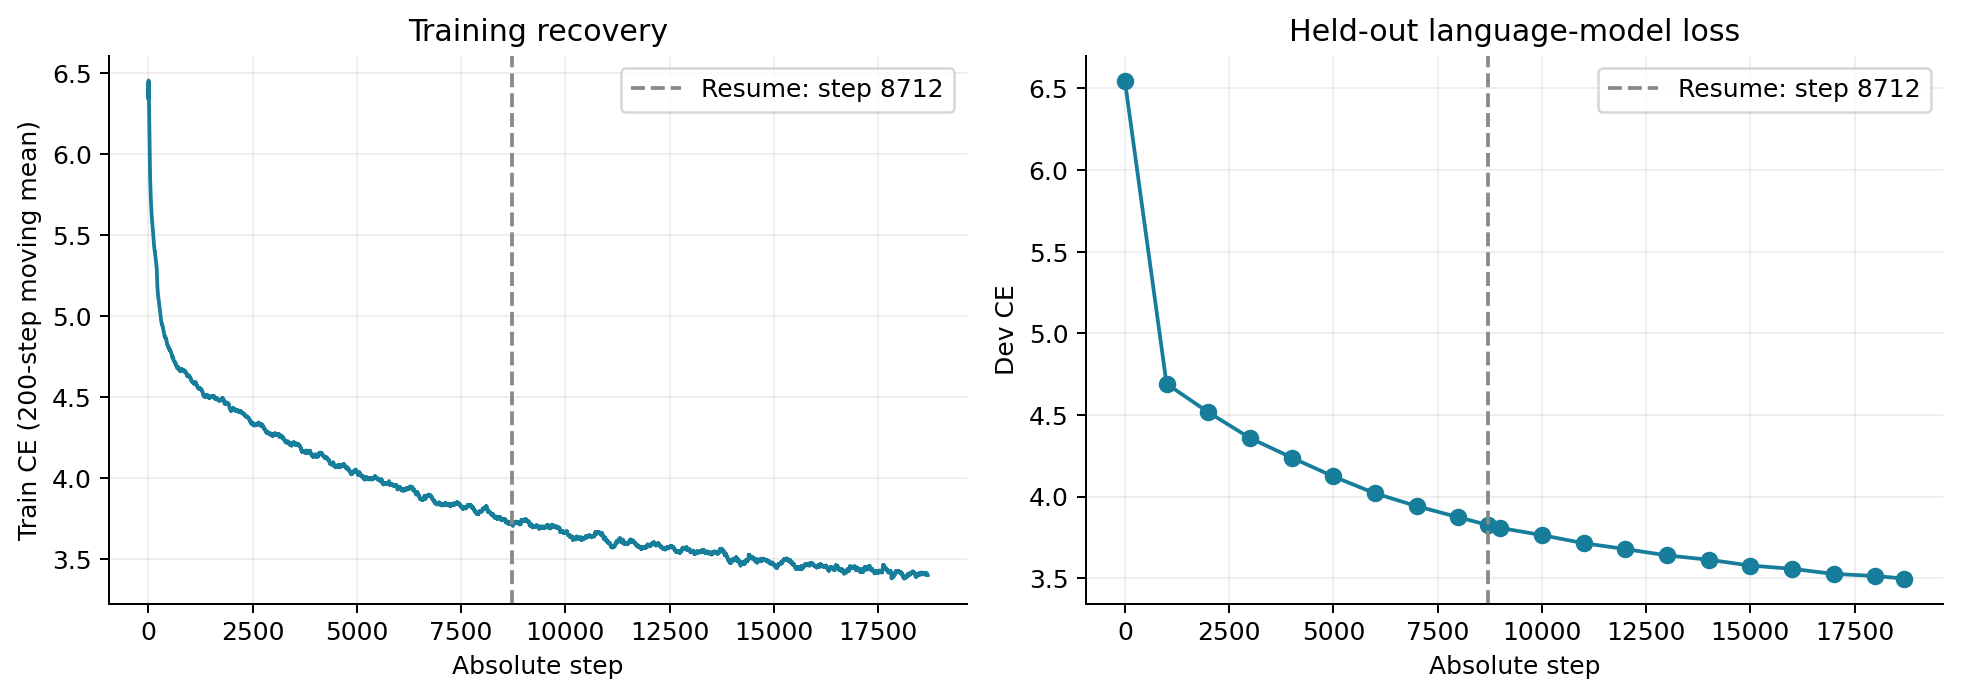

In [3]:
display(Image(filename=str(ROOT/'figures/01_learning_curves.png')))

## LM: основные оценки
PPL = exp(mean next-token CE). 8 фиксированных test blocks. На 8192 между этапами меняется и checkpoint, и dev beta: эффект обучения отдельно не выделяется.

label,DroPE after,DroPE before,RoPE base,"DroPE PPL reduction, %"
length,,,,
2048,30.953,42.658,12.639,27.438
4096,41.232,56.791,76.911,27.398
8192,81.021,85.858,286.877,5.634


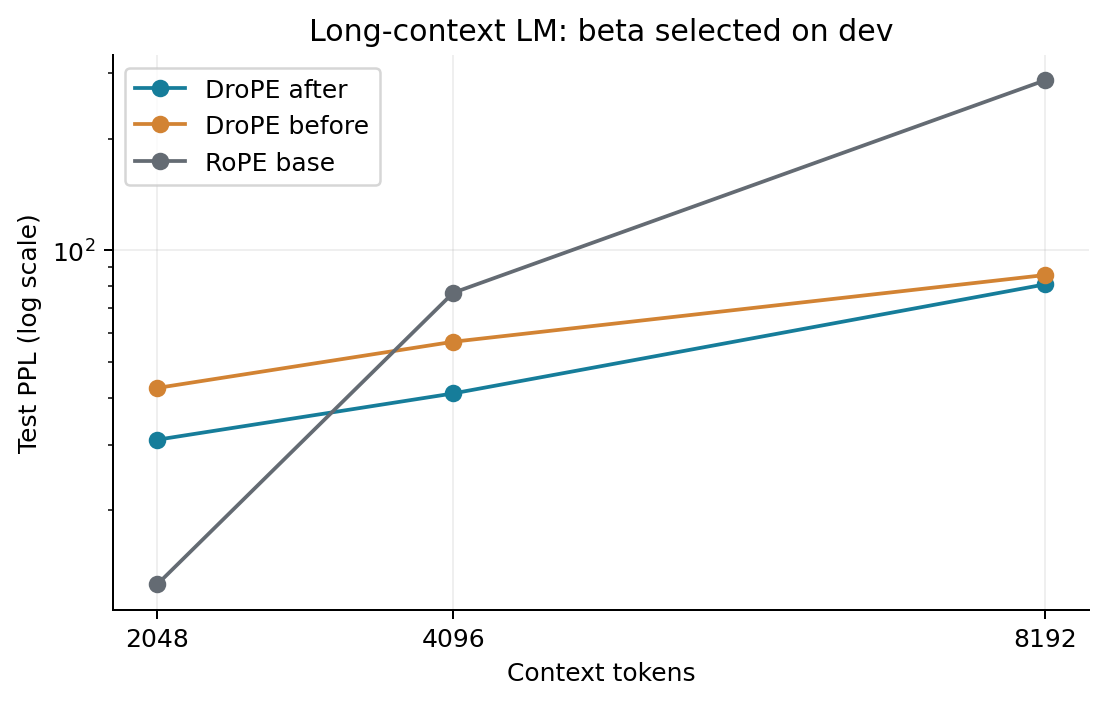

In [4]:
display(comparison.round(3))
display(Image(filename=str(ROOT/'figures/02_context_ppl.png')))

## Масштаб attention
Beta умножает logits один раз. Paper beta отличается от выбранной на маленьком dev (2 блока).

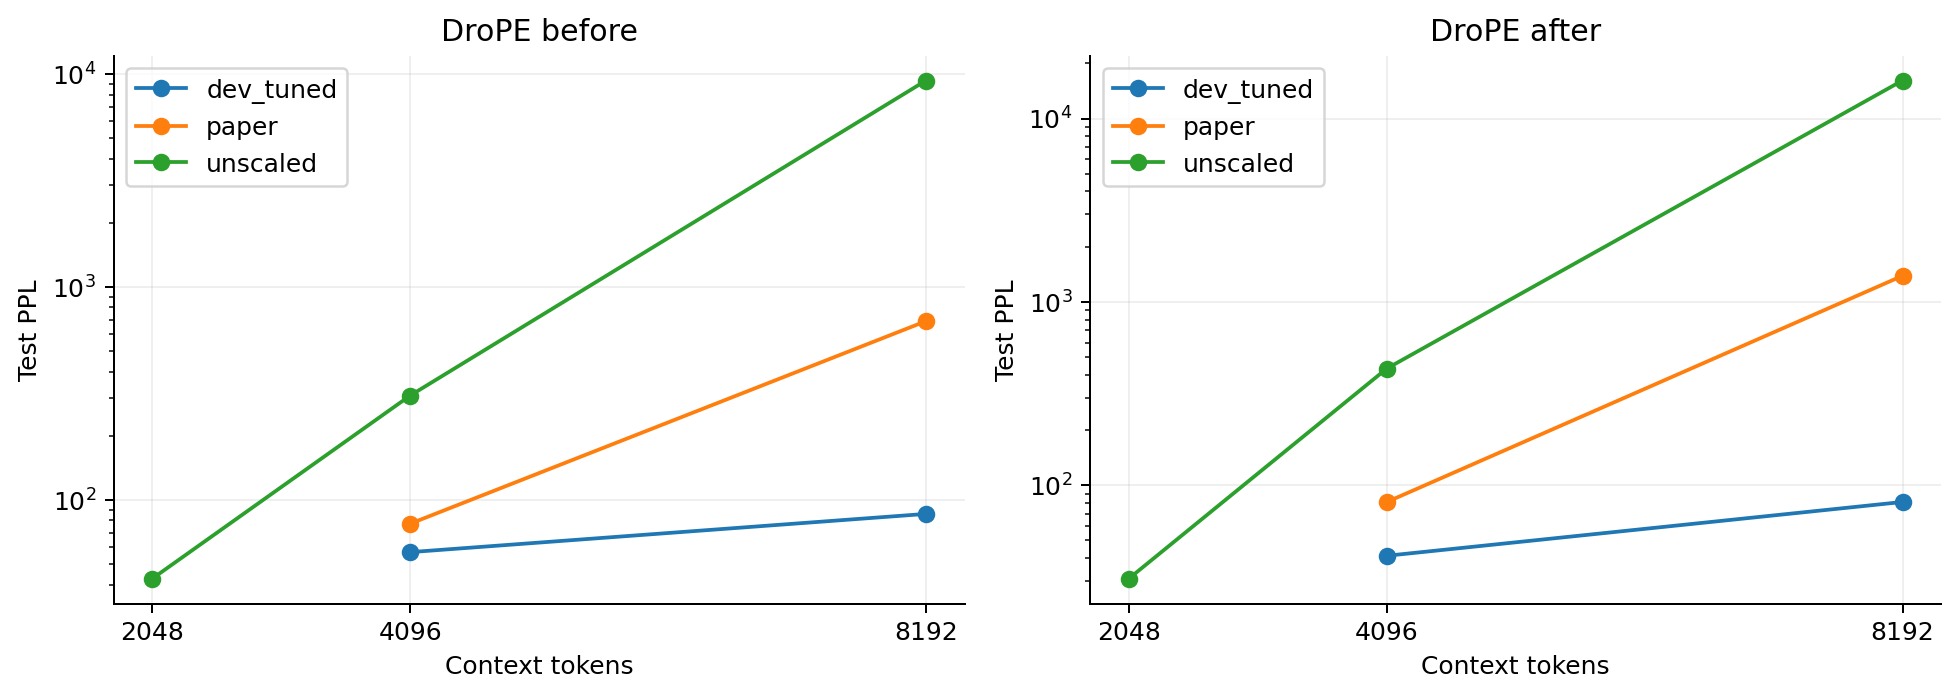

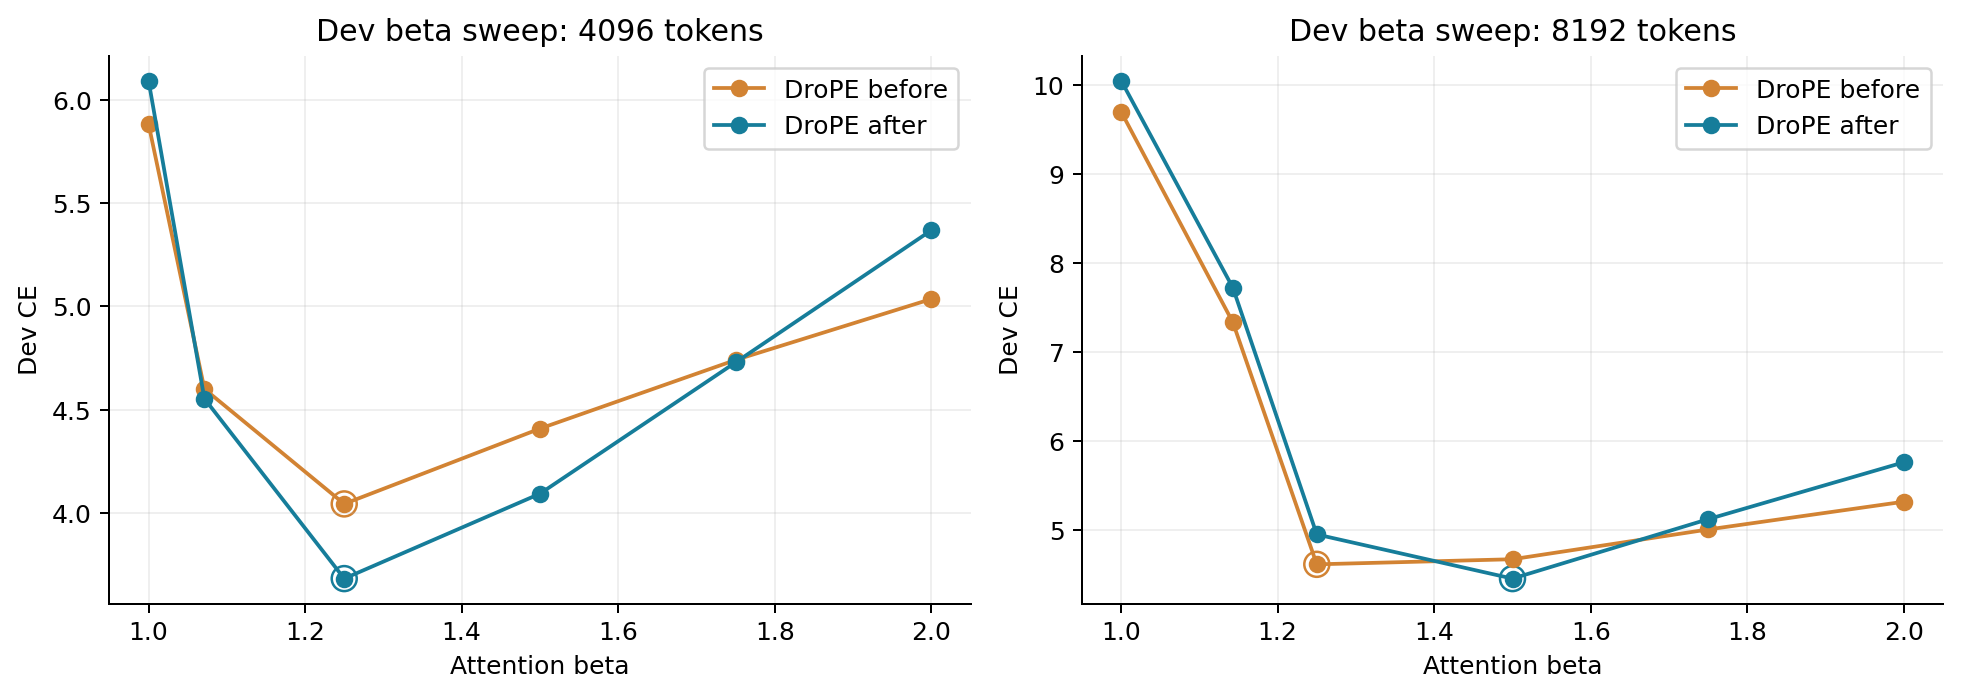

In [5]:
display(Image(filename=str(ROOT/'figures/03_scaling_test.png')))
display(Image(filename=str(ROOT/'figures/04_beta_dev.png')))

## Потери по позиции и сохранённый малый NIAH
NIAH n=2 на ячейку — только диагностика. Не смешиваем его с дополнительным n=8/12.

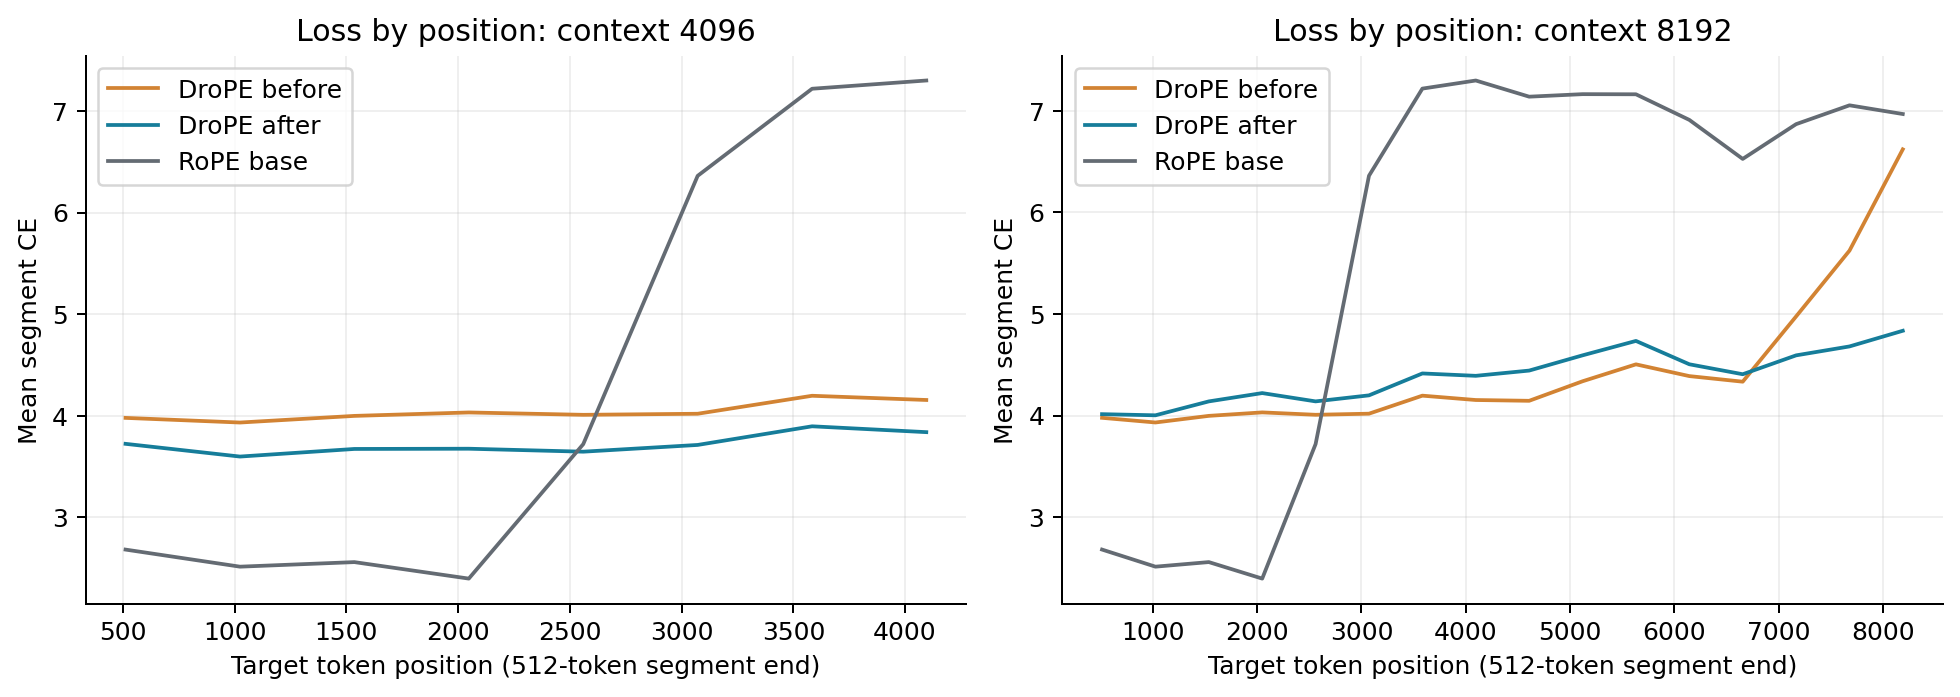

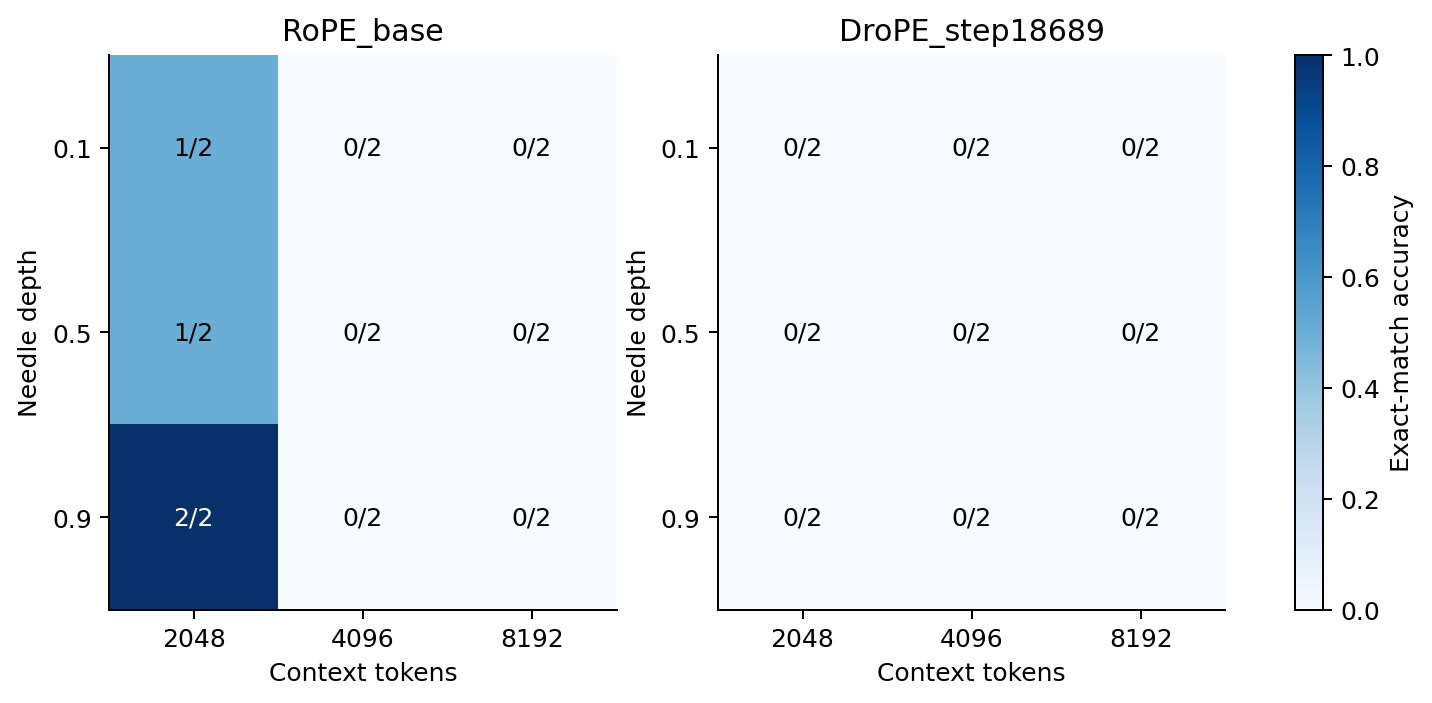

In [6]:
display(Image(filename=str(ROOT/'figures/05_position_loss.png')))
display(Image(filename=str(ROOT/'figures/06_niah.png')))

## YaRN и Dynamic NTK: LM-контроли
Дополнительный архив потерян. CE восстановлены из консоли по блокам; tail с 4 знаками. YaRN исторически имел metadata warning; explicit factor был применён, новая правка повторно не проверена GPU-запуском. Это LM-сравнение, не retrieval-сравнение.

,method,length,ce,ppl,blocks,provenance
0,RoPE base,2048,2.5368,12.6387,8,recovered_from_console
1,RoPE base,4096,4.3427,76.9114,8,recovered_from_console
2,RoPE base,8192,5.6591,286.8767,8,recovered_from_console
3,YaRN,4096,2.4916,12.0800,8,recovered_from_console
4,YaRN,8192,2.4940,12.1094,8,recovered_from_console
5,Dynamic NTK,4096,2.5224,12.4581,8,recovered_from_console
6,Dynamic NTK,8192,2.9579,19.2573,8,recovered_from_console
7,DroPE (dev beta),2048,3.4325,30.9531,8,saved_machine_metrics
8,DroPE (dev beta),4096,3.7192,41.2316,8,saved_machine_metrics
9,DroPE (dev beta),8192,4.3947,81.0210,8,saved_machine_metrics


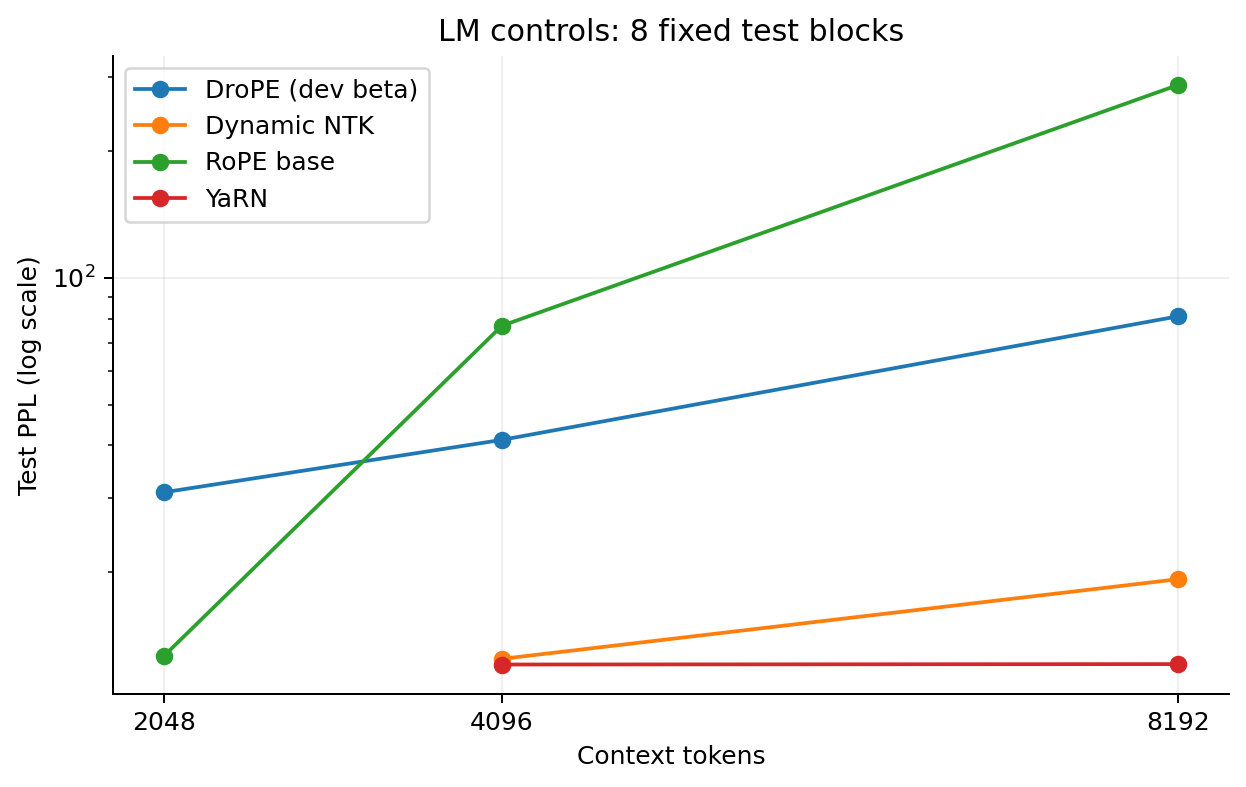

In [7]:
display(pd.read_csv(ROOT/'results/tables/lm_with_baselines.csv')[['method','length','ce','ppl','blocks','provenance']].round(4))
display(Image(filename=str(ROOT/'figures/07_baseline_controls.png')))

## Расширенный NIAH
Greedy, 7-значное извлечённое значение, до 24 new tokens. Коррелированные шаблоны и haystack. DroPE не проходит короткий контроль 512; RoPE проходит 10/12. Это ограничивает интерпретацию длинного теста.

,model,kind,length,depth,correct,n,accuracy,provenance
0,rope,short_control,512,0.9,10,12,0.833333,recovered_from_console
1,rope,main,2048,0.1,3,8,0.375000,recovered_from_console
2,rope,main,2048,0.5,4,8,0.500000,recovered_from_console
3,rope,main,2048,0.9,8,8,1.000000,recovered_from_console
4,drope,short_control,512,0.9,0,12,0.000000,recovered_from_console
5,drope,main,2048,0.1,0,8,0.000000,recovered_from_console
6,drope,main,2048,0.5,0,8,0.000000,recovered_from_console
7,drope,main,2048,0.9,0,8,0.000000,recovered_from_console


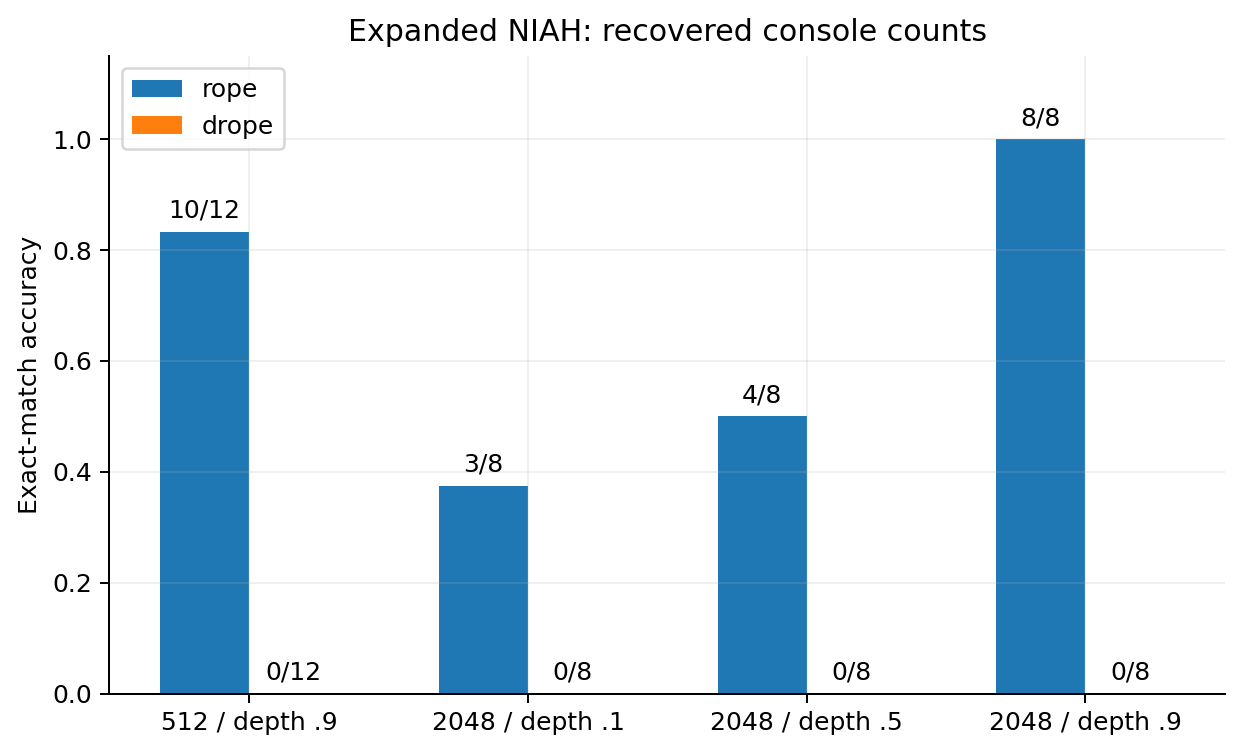

In [8]:
display(pd.read_csv(ROOT/'results/extra/niah_summary.csv'))
display(Image(filename=str(ROOT/'figures/08_niah_expanded.png')))

## Проверки evaluator
Адаптер KV-cache исправляет несовместимость имени keyword в Transformers. Сохранённые численные проверки относятся к основному evaluation; у дополнительного запуска осталась только строка INTEGRITY OK.

In [9]:
display(pd.DataFrame([{'stage':'before',**read(before/'drope/integrity.json')},{'stage':'after',**read(after/'drope/integrity.json')}]))

,stage,prefix_mean_abs_logit_delta,prefix_max_abs_logit_delta,cache_mean_abs_logit_delta,sdpa_eager_mean_abs_logit_delta,sdpa_eager_max_abs_logit_delta,sdpa_ce,eager_ce,ce_delta,suspect,note
0,before,0.017726,0.289062,0.019593,0.017177,0.195312,3.520850,3.521621,0.000771,False,FP16 numerical diagnostic; threshold flags inv...
1,after,0.016067,0.457031,0.017317,0.016173,0.187500,3.211532,3.211605,0.000073,False,FP16 numerical diagnostic; threshold flags inv...


## Вывод
**LM восстановлено частично; исходное качество и retrieval не восстановлены.** На длинном LM DroPE лучше unscaled RoPE, но хуже YaRN/NTK. Бюджет около 0.97% минимального бюджета статьи; нельзя объявлять это опровержением статьи. Отсутствуют equal-token RoPE retraining, несколько seeds и авторский checkpoint. Публичная ссылка на наши веса пока не предоставлена; код запуска с нуля находится в src/.